# 02 — Traditional Machine Learning Experiments

Handcrafted image-feature extraction, training of traditional ML baselines, validation comparison, and diagnostic analysis.

**Environment:** Google Colab with Google Drive mounted. Check paths and prerequisite artifacts before running.

This notebook is carried over from the original experiment notebook. It may rely on saved split CSVs and variables created earlier. Verify the paths and split filenames in the setup cells before running. Do not overwrite the trained ResNet checkpoint.

Stage 2 — Traditional machine learning

In [35]:
PROJECT_DIR = Path('/content/gdrive/MyDrive/CottonGuard-AI')

OUTPUT_DIR = PROJECT_DIR / 'results'
MODEL_DIR = PROJECT_DIR / 'models' / 'traditional_ml'

# Create directories if they do not exist
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

In [23]:
!pip -q install opencv-python-headless

In [ ]:
# 1. Import libraries and load existing dataset splits

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import time

from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42

# Project directories — UPDATED
PROJECT_DIR = Path('/content/gdrive/MyDrive/CottonGuard-AI')
DATA_DIR = Path('/content/gdrive/MyDrive/cotton')

# Existing production dataset splits.
SPLIT_DIR = PROJECT_DIR / 'results' / 'data'

# Model and experiment output directories.
OUTPUT_DIR = PROJECT_DIR / 'results'
MODEL_DIR = PROJECT_DIR / 'models' / 'traditional_ml'

MODEL_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load existing grouped splits.
train_df = pd.read_csv(SPLIT_DIR / 'train_grouped.csv')
val_df = pd.read_csv(SPLIT_DIR / 'validation_grouped.csv')
test_df = pd.read_csv(SPLIT_DIR / 'test_grouped.csv')

# Update image paths to the new Drive mount.
for split_df in [train_df, val_df, test_df]:
    split_df['path'] = split_df['path'].str.replace(
        '/content/drive/MyDrive/',
        '/content/gdrive/MyDrive/',
        regex=False
    )

# Verify required columns.
required_columns = {'path', 'label', 'sha256', 'group_id'}

for split_name, split_df in [
    ('Training', train_df),
    ('Validation', val_df),
    ('Testing', test_df)
]:
    missing = required_columns - set(split_df.columns)

    if missing:
        raise ValueError(
            f"{split_name} split is missing columns: {missing}"
        )

    print(f"{split_name}: {len(split_df)} images")

print("\nExisting grouped splits loaded successfully.")
print("Project directory:", PROJECT_DIR)
print("Split directory:", SPLIT_DIR)

Training: 1126 images
Validation: 239 images
Testing: 226 images

Existing grouped splits loaded successfully.
Project directory: /content/gdrive/MyDrive/CottonGuard-AI
Split directory: /content/gdrive/MyDrive/CottonGuard-AI/results/data


In [25]:
def extract_features(image_path, size=(128, 128)):
    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Cannot read image: {image_path}")

    image = cv2.resize(image, size)
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    gray = gray.astype(np.float32) / 255.0

    features = []

    for theta in [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]:
        for sigma in [2.0, 4.0]:
            kernel = cv2.getGaborKernel(
                (21, 21),
                sigma,
                theta,
                10.0,
                0.5,
                0,
                ktype=cv2.CV_32F
            )

            response = cv2.filter2D(gray, cv2.CV_32F, kernel)

            features.extend([
                np.mean(response),
                np.std(response),
                np.mean(np.abs(response))
            ])

    hsv = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2HSV)

    for channel in range(3):
        histogram = cv2.calcHist(
            [hsv],
            [channel],
            None,
            [16],
            [0, 256] if channel == 0 else
            [0, 256] if channel == 1 else [0, 256]
        )

        histogram = cv2.normalize(
            histogram, None
        ).flatten()

        features.extend(histogram)

    return np.asarray(features, dtype=np.float32)

In [26]:
def build_features(df, dataset_name):
    X = []
    y = []

    for i, row in enumerate(df.itertuples(index=False), start=1):
        features = extract_features(row.path)

        X.append(features)
        y.append(row.label)

        if i % 100 == 0 or i == len(df):
            print(f"{dataset_name}: {i}/{len(df)} images processed")

    return np.asarray(X), np.asarray(y)


start = time.time()

X_train, y_train = build_features(train_df, "Training")
X_val, y_val = build_features(val_df, "Validation")

print("\nTraining feature shape:", X_train.shape)
print("Validation feature shape:", X_val.shape)
print("Feature extraction time:", round(time.time() - start, 2), "seconds")

Training: 100/1126 images processed
Training: 200/1126 images processed
Training: 300/1126 images processed
Training: 400/1126 images processed
Training: 500/1126 images processed
Training: 600/1126 images processed
Training: 700/1126 images processed
Training: 800/1126 images processed
Training: 900/1126 images processed
Training: 1000/1126 images processed
Training: 1100/1126 images processed
Training: 1126/1126 images processed
Validation: 100/239 images processed
Validation: 200/239 images processed
Validation: 239/239 images processed

Training feature shape: (1126, 72)
Validation feature shape: (239, 72)
Feature extraction time: 1153.62 seconds


In [27]:
models = {
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE,
        max_depth=None
    ),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            C=1.0,
            probability=True,
            random_state=RANDOM_STATE
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        class_weight="balanced"
    )
}

results = []
trained_models = {}

for name, model in models.items():
    print(f"\nTraining {name}...")

    start = time.time()
    model.fit(X_train, y_train)

    predictions = model.predict(X_val)
    elapsed = time.time() - start

    trained_models[name] = model

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision_macro": precision_score(
            y_val, predictions, average="macro", zero_division=0
        ),
        "Recall_macro": recall_score(
            y_val, predictions, average="macro", zero_division=0
        ),
        "F1_macro": f1_score(
            y_val, predictions, average="macro", zero_division=0
        ),
        "Training_and_prediction_seconds": round(elapsed, 2)
    })

results_df = pd.DataFrame(results).sort_values(
    "F1_macro", ascending=False
)

display(results_df.round(4))


Training KNN...

Training Decision Tree...

Training SVM...

Training Random Forest...


,Model,Accuracy,Precision_macro,Recall_macro,F1_macro,Training_and_prediction_seconds
3,Random Forest,0.9749,0.9727,0.9740,0.9732,2.04
2,SVM,0.9372,0.9435,0.9358,0.9388,0.40
1,Decision Tree,0.9038,0.9046,0.9089,0.9060,0.08
0,KNN,0.8745,0.8764,0.8699,0.8704,0.08


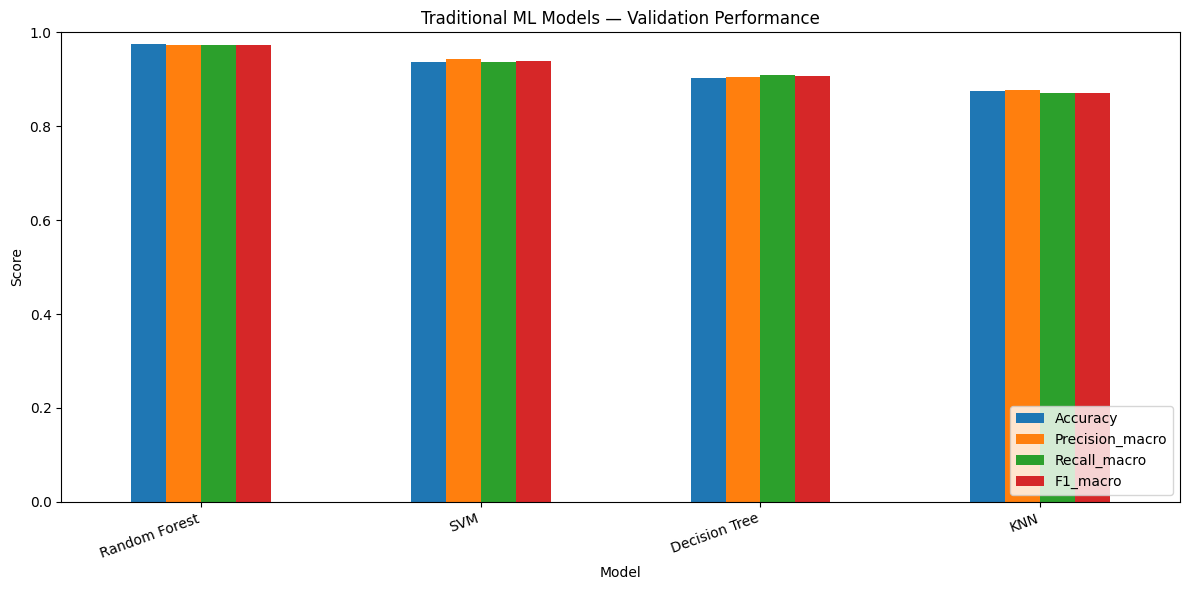

In [28]:
results_df.set_index("Model")[
    ["Accuracy", "Precision_macro", "Recall_macro", "F1_macro"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Traditional ML Models — Validation Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Best validation model: Random Forest

Classification report:
                  precision    recall  f1-score   support

bacterial_blight       0.99      0.99      0.99        77
      curl_virus       0.94      0.98      0.96        48
  fussarium_wilt       1.00      1.00      1.00        57
         healthy       0.96      0.93      0.95        57

        accuracy                           0.97       239
       macro avg       0.97      0.97      0.97       239
    weighted avg       0.98      0.97      0.97       239



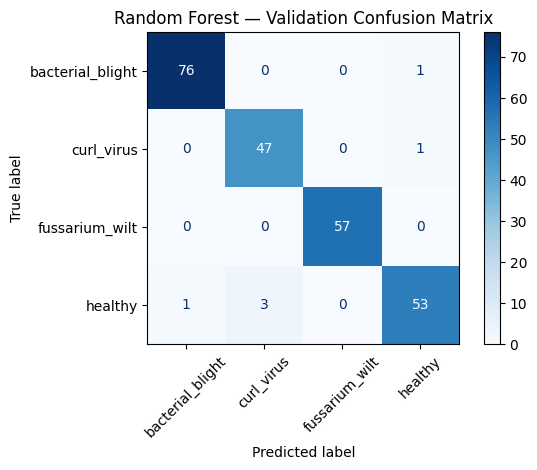

In [29]:
best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]

val_predictions = best_model.predict(X_val)

print("Best validation model:", best_name)

print("\nClassification report:")
print(classification_report(
    y_val,
    val_predictions,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_predictions,
    labels=sorted(np.unique(y_train)),
    xticks_rotation=45,
    cmap="Blues"
)

plt.title(f"{best_name} — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [30]:
results_df.to_csv(
    OUTPUT_DIR / "traditional_ml_validation_results.csv",
    index=False
)

for name, model in trained_models.items():
    filename = name.lower().replace(" ", "_") + ".joblib"
    joblib.dump(model, MODEL_DIR / filename)

print("Validation results and trained models saved.")

Validation results and trained models saved.


Class order: [np.str_('bacterial_blight'), np.str_('curl_virus'), np.str_('fussarium_wilt'), np.str_('healthy')]
[[76  0  0  1]
 [ 0 47  0  1]
 [ 0  0 57  0]
 [ 1  3  0 53]]


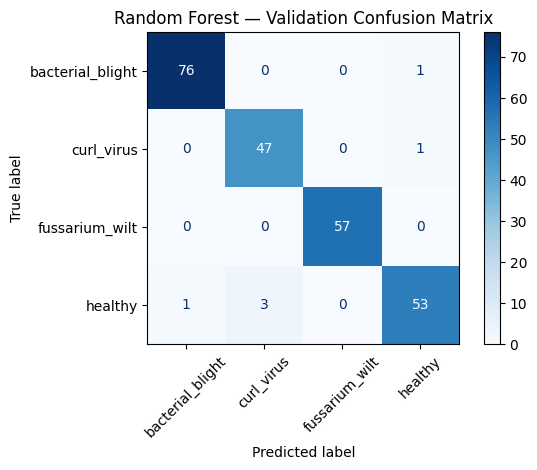

In [31]:
# Audit the high accuracy

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

val_predictions = best_model.predict(X_val)

labels = sorted(set(y_train) | set(y_val))

cm = confusion_matrix(
    y_val,
    val_predictions,
    labels=labels
)

print("Class order:", labels)
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
).plot(
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("Random Forest — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
# Verify grouped dataset split integrity

train_groups = set(train_df["group_id"])
val_groups = set(val_df["group_id"])
test_groups = set(test_df["group_id"])

print("Train-validation overlap:",
      len(train_groups & val_groups))

print("Train-test overlap:",
      len(train_groups & test_groups))

print("Validation-test overlap:",
      len(val_groups & test_groups))

assert not (train_groups & val_groups)
assert not (train_groups & test_groups)
assert not (val_groups & test_groups)

print("\nSUCCESS: No group leakage detected.")

Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0

SUCCESS: No group leakage detected.


Misclassified images: 6


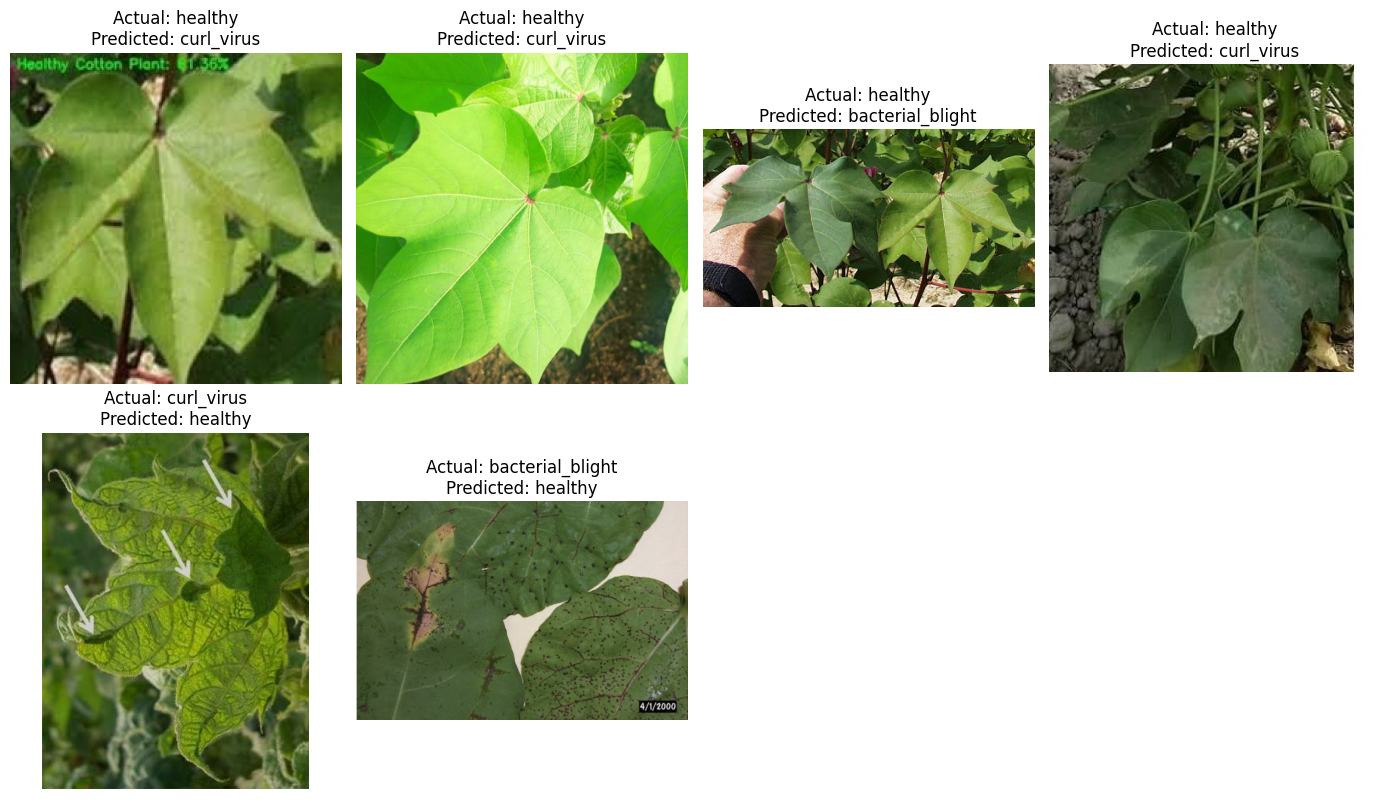

In [33]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

wrong_indices = np.where(val_predictions != y_val)[0]

print("Misclassified images:", len(wrong_indices))

if len(wrong_indices) > 0:
    n = min(12, len(wrong_indices))
    fig, axes = plt.subplots(
        int(np.ceil(n / 4)), 4,
        figsize=(14, 4 * int(np.ceil(n / 4)))
    )

    axes = np.array(axes).reshape(-1)

    for ax, idx in zip(axes, wrong_indices[:n]):
        row = val_df.iloc[idx]

        image = cv2.imread(row["path"])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        ax.imshow(image)
        ax.set_title(
            f"Actual: {y_val[idx]}\nPredicted: {val_predictions[idx]}"
        )
        ax.axis("off")

    for ax in axes[n:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No validation errors to display.")

In [43]:
print("PROJECT_DIR =", PROJECT_DIR)
print("OUTPUT_DIR  =", OUTPUT_DIR)
print("OUTPUT_DIR type =", type(OUTPUT_DIR))

print("\nDoes the old path exist?", Path('/content/drive/MyDrive/CottonGuard-AI/results').exists())
print("Does the new path exist?", Path('/content/gdrive/MyDrive/CottonGuard-AI/results').exists())

PROJECT_DIR = /content/gdrive/MyDrive/CottonGuard-AI
OUTPUT_DIR  = /content/drive/MyDrive/CottonGuard-AI/results
OUTPUT_DIR type = <class 'pathlib._local.PosixPath'>

Does the old path exist? False
Does the new path exist? True


In [45]:
OUTPUT_DIR = Path('/content/gdrive/MyDrive/CottonGuard-AI/results')

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("\nCorrected OUTPUT_DIR:", OUTPUT_DIR)
print("Directory exists:", OUTPUT_DIR.is_dir())


Corrected OUTPUT_DIR: /content/gdrive/MyDrive/CottonGuard-AI/results
Directory exists: True


In [46]:
test_file = OUTPUT_DIR / "path_test.txt"
test_file.write_text("Google Drive path is working.")

print("Test file saved:", test_file.exists())

Test file saved: True


In [52]:
from pathlib import Path

OUTPUT_DIR = Path('/content/gdrive/MyDrive/CottonGuard-AI/results')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

save_path = OUTPUT_DIR / "traditional_ml_validation_results.csv"

print("Saving to:", save_path)
print("Directory exists:", OUTPUT_DIR.is_dir())

results_df.to_csv(save_path, index=False)

print("Saved successfully:", save_path.exists())

Saving to: /content/gdrive/MyDrive/CottonGuard-AI/results/traditional_ml_validation_results.csv
Directory exists: True
Saved successfully: True
